# 06 — Fixed HNSW and three-backend retrieval
The independent `chemicalspace_new/package_00` 1K pilot is separate from the `scale_100k_00` parent. The parent uses the same 100 held-out queries and original index prefixes at 1K, 10K and 100K. Each size builds a **fresh graph**, with M=16, efConstruction=200, efSearch=200, one construction thread and sequential single-query `knnQuery` calls. No parameter sweep or 100M extrapolation.

See [methodology and local observations](../docs/hnsw.md). Modules own execution; this notebook selects the four authorized runs and presents their evidence.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from chemtellect import exact_retrieval as exact
from chemtellect import hnsw_adapter as hnsw
from chemtellect import hnsw_benchmark as comparison
from chemtellect.hnsw_reporting import tables, write_charts
from chemtellect.fingerprints import validate_nonzero_fingerprints

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/chemtellect').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Start Jupyter within the repository.')
configuration = json.loads((ROOT/'experiments/configs/hnsw_v1.json').read_text())
if configuration != hnsw.CONFIGURATION:
    raise ValueError('Only the approved single HNSW configuration is allowed.')
ARTIFACTS = {
    'package_00': ROOT/'data/processed/chemicalspace_new/package_00/fingerprints/628c36671feeb38e1a97a34dd664bb54f43851374fcea4190a474479a12df427',
    'scale_100k_00': ROOT/'data/processed/chemicalspace_new/scale_100k_00/fingerprints/d2b04c1e24357f16ff9a8609e0aa2349eccade282d596da005afc8563edd4d3e',
}
JOBS = [('package_00', 1000), ('scale_100k_00', 1000), ('scale_100k_00', 10000), ('scale_100k_00', 100000)]

Your CPU supports instructions that this binary was not compiled to use: SSE3 SSE4.1 SSE4.2 AVX AVX2
For maximum performance, you can install NMSLIB from sources 
pip install --no-binary :all: nmslib


## Verify explicit inputs
The parent was prepared with the existing overview workflow and unchanged configuration: all eligible unique structures described, seed 42, 100 queries, first-physical-line representatives and the original canonicalization. Fingerprints use the approved Morgan configuration. No split or raw data is changed by this notebook. Missing or corrupt inputs stop; no fallback data is selected.

In [3]:
provenance = []
parent_queries = None
for package, size in JOBS:
    manifest, queries, index, records, _ = exact.load_selection(ROOT, ARTIFACTS[package], size)
    if manifest['source'] != 'chemicalspace_new' or manifest['package'] != package or len(queries) != 100 or len(index) != size:
        raise ValueError('Unexpected input selection.')
    raw = comparison.verify_raw(ROOT, manifest)
    guard = validate_nonzero_fingerprints(queries, index, records)
    if package == 'scale_100k_00':
        if parent_queries is not None and parent_queries != records['queries']:
            raise ValueError('Parent held-out queries changed between sizes.')
        parent_queries = records['queries']
    provenance.append({'Package': package, 'Index size': size, 'Queries': len(queries),
        'Split': manifest['split_id'], 'Artifact': manifest['artifact_id'], 'Raw SHA-256': raw['sha256'],
        'All selected rows nonzero': guard['query_zero_rows'] == guard['index_zero_rows'] == 0})
display(pd.DataFrame(provenance).set_index(['Package', 'Index size']))

Queries  \
Package       Index size            
package_00    1000            100   
scale_100k_00 1000            100   
              10000           100   
              100000          100   

                                                                      Split  \
Package       Index size                                                      
package_00    1000        f85552ea5b17e4829a09df82c79ad3bb2d762ee672c0f5...   
scale_100k_00 1000        4141f1864e80bc91e9d064df766dd038eae7210792107f...   
              10000       4141f1864e80bc91e9d064df766dd038eae7210792107f...   
              100000      4141f1864e80bc91e9d064df766dd038eae7210792107f...   

                                                                   Artifact  \
Package       Index size                                                      
package_00    1000        628c36671feeb38e1a97a34dd664bb54f43851374fcea4...   
scale_100k_00 1000        d2b04c1e24357f16ff9a8609e0aa2349eccade282d596d...   
              10000       d2b04c1e24357f16ff9a8609e0aa2349eccade282d596d...   
              100000      d2b04c1e24357f16ff9a8609e0aa2349eccade282d596d...   

                                                                Raw SHA-256  \
Package       Index size                                                      
package_00    1000        f3b298720497eb4ada39fa0dcfdf85f2c5851922ea8d04...   
scale_100k_00 1000        b77428937326c99f80cb28b1d0b3be549d9663fbf11cde...   
              10000       b77428937326c99f80cb28b1d0b3be549d9663fbf11cde...   
              100000      b77428937326c99f80cb28b1d0b3be549d9663fbf11cde...   

                          All selected rows nonzero  
Package       Index size                             
package_00    1000                             True  
scale_100k_00 1000                             True  
              10000                            True  
              100000                           True

## Run or inspect completed evidence
Default inspection does not write to completed runs. Set `RUN_NEW=True` to execute these same four authorized selections into new unique folders. Every comparison computes and saves its own fresh exhaustive float64 matrix before retrieval timing. The saved historical 1K timings are never used as timed queries or speedup denominators. A failed correctness gate preserves evidence and prevents comparative speed publication.

In [4]:
RUN_NEW = False
COMPLETED_RUNS = ['experiments/results/hnsw/chemicalspace_new/package_00/628c36671feeb38e1a97a34dd664bb54f43851374fcea4190a474479a12df427/index_1000/run_75f61d87dfa44f4882900afc33e66059', 'experiments/results/hnsw/chemicalspace_new/scale_100k_00/d2b04c1e24357f16ff9a8609e0aa2349eccade282d596da005afc8563edd4d3e/index_1000/run_a643e3771f9a4e4c89da11267536c3cd', 'experiments/results/hnsw/chemicalspace_new/scale_100k_00/d2b04c1e24357f16ff9a8609e0aa2349eccade282d596da005afc8563edd4d3e/index_10000/run_12af60d158174d8da426582309696a52', 'experiments/results/hnsw/chemicalspace_new/scale_100k_00/d2b04c1e24357f16ff9a8609e0aa2349eccade282d596da005afc8563edd4d3e/index_100000/run_6fb4c2508add4650915235886427f110']

if RUN_NEW:
    paths = []
    for package, size in JOBS:
        path, report = comparison.run_comparison(ROOT, ARTIFACTS[package], size,
            expected_selection={'source': 'chemicalspace_new', 'package': package, 'query_count': 100, 'index_size': size},
            report_writer=write_charts)
        paths.append(path)
else:
    if len(COMPLETED_RUNS) != len(JOBS):
        raise ValueError('Select the four explicit completed run paths, or RUN_NEW=True.')
    paths = [ROOT/p for p in COMPLETED_RUNS]
reports = [comparison.load_comparison_run(p, ROOT) for p in paths]
for (package, size), report in zip(JOBS, reports):
    if report['package'] != package or report['index_size'] != size or report['query_count'] != 100:
        raise ValueError('Completed run does not match the explicit selection.')
print('Verified run folders:')
for path in paths:
    print(path.relative_to(ROOT))

Verified run folders:
experiments/results/hnsw/chemicalspace_new/package_00/628c36671feeb38e1a97a34dd664bb54f43851374fcea4190a474479a12df427/index_1000/run_75f61d87dfa44f4882900afc33e66059
experiments/results/hnsw/chemicalspace_new/scale_100k_00/d2b04c1e24357f16ff9a8609e0aa2349eccade282d596da005afc8563edd4d3e/index_1000/run_a643e3771f9a4e4c89da11267536c3cd
experiments/results/hnsw/chemicalspace_new/scale_100k_00/d2b04c1e24357f16ff9a8609e0aa2349eccade282d596da005afc8563edd4d3e/index_10000/run_12af60d158174d8da426582309696a52
experiments/results/hnsw/chemicalspace_new/scale_100k_00/d2b04c1e24357f16ff9a8609e0aa2349eccade282d596da005afc8563edd4d3e/index_100000/run_6fb4c2508add4650915235886427f110


## independent pilot: package_00 / 1,000

**Provenance**

,Value
source,chemicalspace_new
package,package_00
experiment,independent pilot
query_count,100
index_size,1000
artifact_id,628c36671feeb38e1a97a34dd664bb54f43851374fcea4...
split_id,f85552ea5b17e4829a09df82c79ad3bb2d762ee672c0f5...
raw_sha256_inherited,f3b298720497eb4ada39fa0dcfdf85f2c5851922ea8d04...
Git revision,8b3686f8bade5cd902ed600f6840aa45801141b1
validation passed,True


**Configuration**

,Value
concurrent_queries,1
data_type,OBJECT_AS_STRING
dtype,FLOAT
index_params,"{'M': 16, 'efConstruction': 200, 'indexThreadQ..."
method,hnsw
query_api,knnQuery
query_params,{'efSearch': 200}
space,bit_jaccard


**Correctness**

... (7 outputs left out)

**Tie-aware top-k recall**

,,mean,median,minimum,query_count
Backend,k,,,,
rdkit,10,1.000,1.0,1.00,100
fpsim2,10,1.000,1.0,1.00,100
hnsw,10,0.999,1.0,0.90,100
rdkit,25,1.000,1.0,1.00,100
fpsim2,25,1.000,1.0,1.00,100
hnsw,25,1.000,1.0,0.96,100
rdkit,50,1.000,1.0,1.00,100
fpsim2,50,1.000,1.0,1.00,100
hnsw,50,1.000,1.0,0.98,100


**Top-k-limited threshold recall**

defined_queries  empty_queries mean_defined_recall  \
Backend k   Threshold                                                       
rdkit   10  0.3                     50             50            0.953355   
            0.5                      1             99                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
fpsim2  10  0.3                     50             50            0.953355   
            0.5                      1             99                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
hnsw    10  0.3                     50             50            0.953355   
            0.5                      1             99                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
rdkit   25  0.3                     50             50            0.999231   
            0.5                      1             99                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
fpsim2  25  0.3                     50             50            0.999231   
            0.5                      1             99                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
hnsw    25  0.3                     50             50            0.999231   
            0.5                      1             99                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
rdkit   50  0.3                     50             50                 1.0   
            0.5                      1             99                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
fpsim2  50  0.3                     50             50                 1.0   
            0.5                      1             99                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
hnsw    50  0.3                     50             50                 1.0   
            0.5                      1             99                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
rdkit   100 0.3                     50             50                 1.0   
            0.5                      1             99                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
fpsim2  100 0.3                     50             50                 1.0   
            0.5                      1             99                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
hnsw    100 0.3                     50             50                 1.0   
            0.5                      1             99                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   

                       total_qualifying_records  
Backend k   Threshold                            
rdkit   10  0.3                             184  
            0.5       

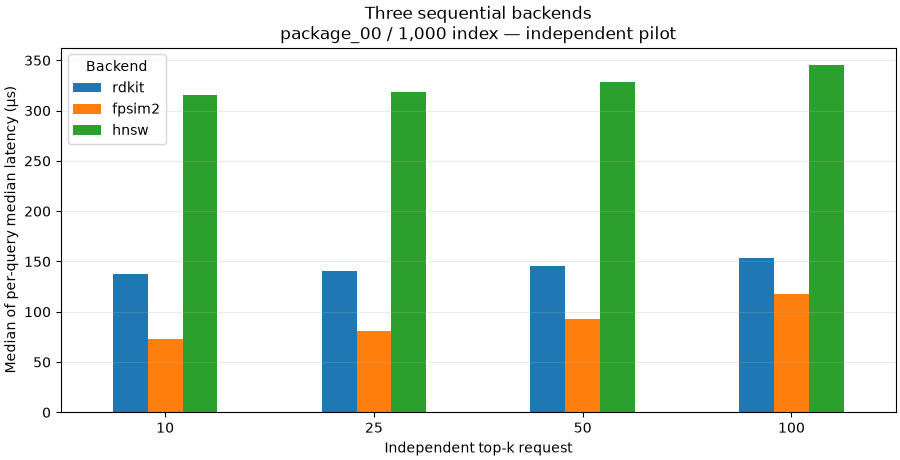

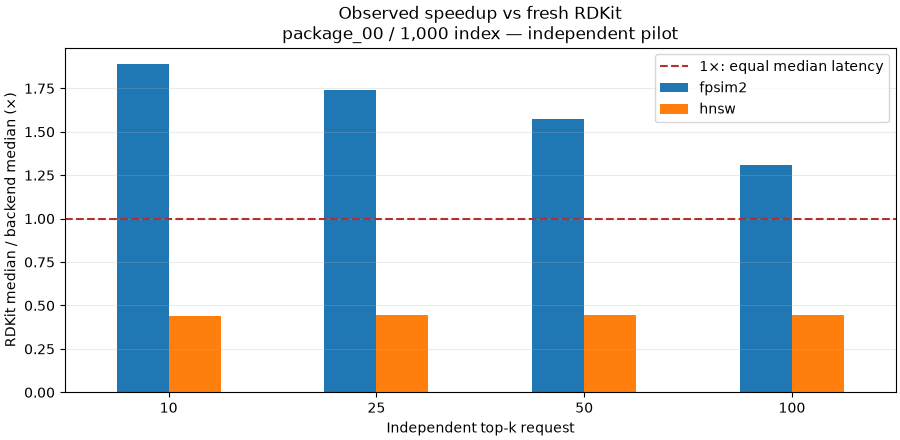

## nested parent scaling: scale_100k_00 / 1,000

**Provenance**

,Value
source,chemicalspace_new
package,scale_100k_00
experiment,nested parent scaling
query_count,100
index_size,1000
artifact_id,d2b04c1e24357f16ff9a8609e0aa2349eccade282d596d...
split_id,4141f1864e80bc91e9d064df766dd038eae7210792107f...
raw_sha256_inherited,b77428937326c99f80cb28b1d0b3be549d9663fbf11cde...
Git revision,8b3686f8bade5cd902ed600f6840aa45801141b1
validation passed,True


**Configuration**

,Value
concurrent_queries,1
data_type,OBJECT_AS_STRING
dtype,FLOAT
index_params,"{'M': 16, 'efConstruction': 200, 'indexThreadQ..."
method,hnsw
query_api,knnQuery
query_params,{'efSearch': 200}
space,bit_jaccard


**Correctness**

... (7 outputs left out)

**Tie-aware top-k recall**

,,mean,median,minimum,query_count
Backend,k,,,,
rdkit,10,1.0,1.0,1.00,100
fpsim2,10,1.0,1.0,1.00,100
hnsw,10,1.0,1.0,1.00,100
rdkit,25,1.0,1.0,1.00,100
fpsim2,25,1.0,1.0,1.00,100
hnsw,25,1.0,1.0,1.00,100
rdkit,50,1.0,1.0,1.00,100
fpsim2,50,1.0,1.0,1.00,100
hnsw,50,1.0,1.0,0.98,100


**Top-k-limited threshold recall**

defined_queries  empty_queries mean_defined_recall  \
Backend k   Threshold                                                       
rdkit   10  0.3                     48             52            0.925501   
            0.5                      4             96                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
fpsim2  10  0.3                     48             52            0.925501   
            0.5                      4             96                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
hnsw    10  0.3                     48             52            0.925501   
            0.5                      4             96                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
rdkit   25  0.3                     48             52            0.992496   
            0.5                      4             96                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
fpsim2  25  0.3                     48             52            0.992496   
            0.5                      4             96                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
hnsw    25  0.3                     48             52            0.992496   
            0.5                      4             96                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
rdkit   50  0.3                     48             52                 1.0   
            0.5                      4             96                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
fpsim2  50  0.3                     48             52                 1.0   
            0.5                      4             96                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
hnsw    50  0.3                     48             52                 1.0   
            0.5                      4             96                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
rdkit   100 0.3                     48             52                 1.0   
            0.5                      4             96                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
fpsim2  100 0.3                     48             52                 1.0   
            0.5                      4             96                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   
hnsw    100 0.3                     48             52                 1.0   
            0.5                      4             96                 1.0   
            0.7                      0            100           undefined   
            0.9                      0            100           undefined   

                       total_qualifying_records  
Backend k   Threshold                            
rdkit   10  0.3                             264  
            0.5       

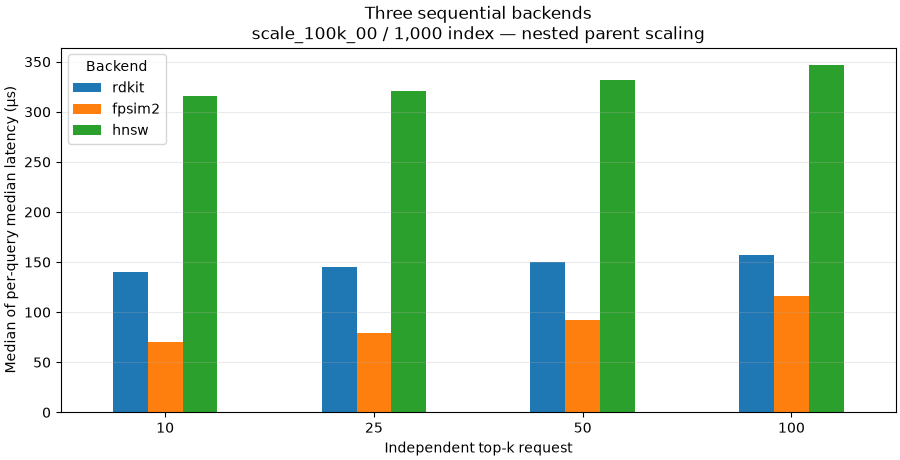

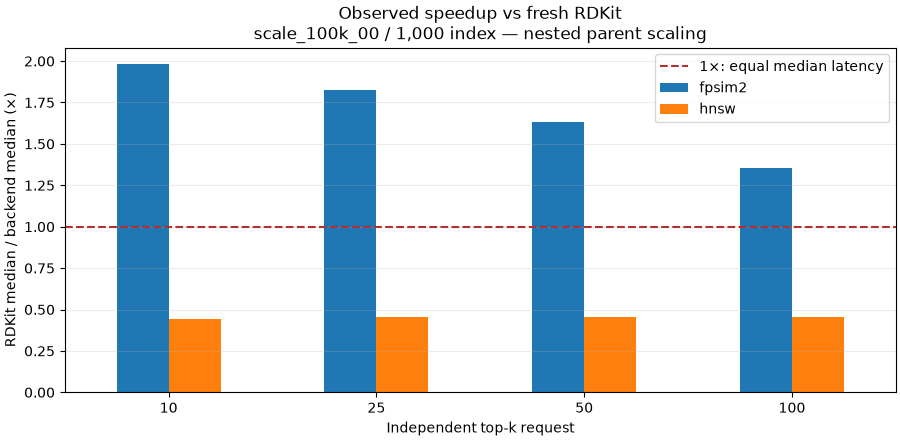

## nested parent scaling: scale_100k_00 / 10,000

**Provenance**

,Value
source,chemicalspace_new
package,scale_100k_00
experiment,nested parent scaling
query_count,100
index_size,10000
artifact_id,d2b04c1e24357f16ff9a8609e0aa2349eccade282d596d...
split_id,4141f1864e80bc91e9d064df766dd038eae7210792107f...
raw_sha256_inherited,b77428937326c99f80cb28b1d0b3be549d9663fbf11cde...
Git revision,8b3686f8bade5cd902ed600f6840aa45801141b1
validation passed,True


**Configuration**

,Value
concurrent_queries,1
data_type,OBJECT_AS_STRING
dtype,FLOAT
index_params,"{'M': 16, 'efConstruction': 200, 'indexThreadQ..."
method,hnsw
query_api,knnQuery
query_params,{'efSearch': 200}
space,bit_jaccard


**Correctness**

... (7 outputs left out)

**Tie-aware top-k recall**

,,mean,median,minimum,query_count
Backend,k,,,,
rdkit,10,1.000,1.0,1.00,100
fpsim2,10,1.000,1.0,1.00,100
hnsw,10,0.997,1.0,0.80,100
rdkit,25,1.000,1.0,1.00,100
fpsim2,25,1.000,1.0,1.00,100
hnsw,25,0.998,1.0,0.92,100
rdkit,50,1.000,1.0,1.00,100
fpsim2,50,1.000,1.0,1.00,100
hnsw,50,0.996,1.0,0.96,100


**Top-k-limited threshold recall**

defined_queries  empty_queries mean_defined_recall  \
Backend k   Threshold                                                       
rdkit   10  0.3                     90             10            0.775126   
            0.5                     16             84            0.943015   
            0.7                      1             99                 1.0   
            0.9                      0            100           undefined   
fpsim2  10  0.3                     90             10            0.775126   
            0.5                     16             84            0.943015   
            0.7                      1             99                 1.0   
            0.9                      0            100           undefined   
hnsw    10  0.3                     90             10            0.775126   
            0.5                     16             84            0.943015   
            0.7                      1             99                 1.0   
            0.9                      0            100           undefined   
rdkit   25  0.3                     90             10            0.881297   
            0.5                     16             84                 1.0   
            0.7                      1             99                 1.0   
            0.9                      0            100           undefined   
fpsim2  25  0.3                     90             10            0.881297   
            0.5                     16             84                 1.0   
            0.7                      1             99                 1.0   
            0.9                      0            100           undefined   
hnsw    25  0.3                     90             10            0.881297   
            0.5                     16             84                 1.0   
            0.7                      1             99                 1.0   
            0.9                      0            100           undefined   
rdkit   50  0.3                     90             10            0.927985   
            0.5                     16             84                 1.0   
            0.7                      1             99                 1.0   
            0.9                      0            100           undefined   
fpsim2  50  0.3                     90             10            0.927985   
            0.5                     16             84                 1.0   
            0.7                      1             99                 1.0   
            0.9                      0            100           undefined   
hnsw    50  0.3                     90             10            0.927985   
            0.5                     16             84                 1.0   
            0.7                      1             99                 1.0   
            0.9                      0            100           undefined   
rdkit   100 0.3                     90             10            0.962319   
            0.5                     16             84                 1.0   
            0.7                      1             99                 1.0   
            0.9                      0            100           undefined   
fpsim2  100 0.3                     90             10            0.962319   
            0.5                     16             84                 1.0   
            0.7                      1             99                 1.0   
            0.9                      0            100           undefined   
hnsw    100 0.3                     90             10            0.962319   
            0.5                     16             84                 1.0   
            0.7                      1             99                 1.0   
            0.9                      0            100           undefined   

                       total_qualifying_records  
Backend k   Threshold                            
rdkit   10  0.3                            2521  
            0.5       

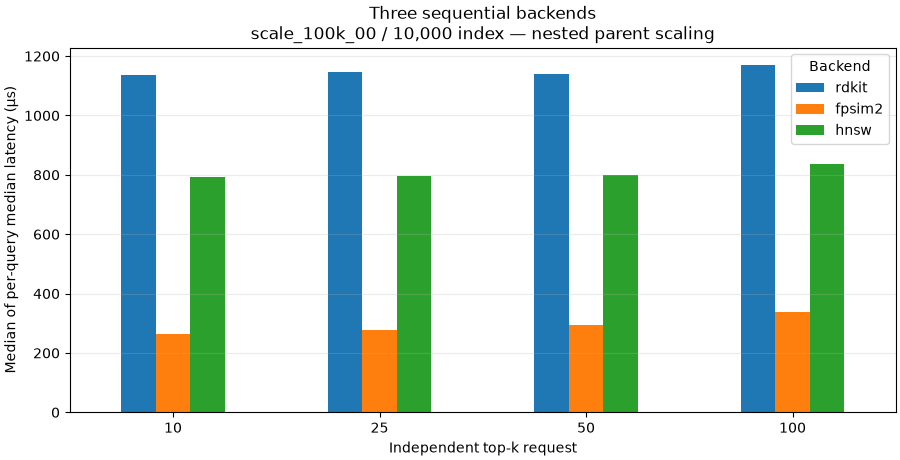

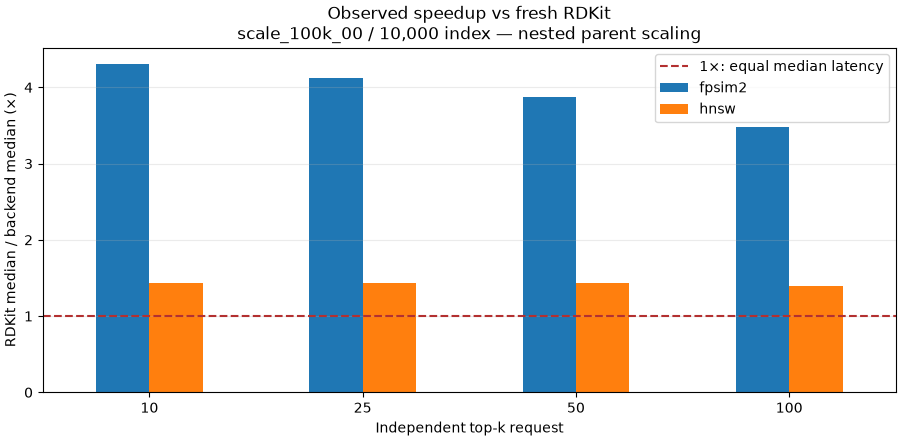

## nested parent scaling: scale_100k_00 / 100,000

**Provenance**

,Value
source,chemicalspace_new
package,scale_100k_00
experiment,nested parent scaling
query_count,100
index_size,100000
artifact_id,d2b04c1e24357f16ff9a8609e0aa2349eccade282d596d...
split_id,4141f1864e80bc91e9d064df766dd038eae7210792107f...
raw_sha256_inherited,b77428937326c99f80cb28b1d0b3be549d9663fbf11cde...
Git revision,8b3686f8bade5cd902ed600f6840aa45801141b1
validation passed,True


**Configuration**

,Value
concurrent_queries,1
data_type,OBJECT_AS_STRING
dtype,FLOAT
index_params,"{'M': 16, 'efConstruction': 200, 'indexThreadQ..."
method,hnsw
query_api,knnQuery
query_params,{'efSearch': 200}
space,bit_jaccard


**Correctness**

... (7 outputs left out)

**Tie-aware top-k recall**

,,mean,median,minimum,query_count
Backend,k,,,,
rdkit,10,1.000,1.00,1.00,100
fpsim2,10,1.000,1.00,1.00,100
hnsw,10,0.993,1.00,0.80,100
rdkit,25,1.000,1.00,1.00,100
fpsim2,25,1.000,1.00,1.00,100
hnsw,25,0.995,1.00,0.88,100
rdkit,50,1.000,1.00,1.00,100
fpsim2,50,1.000,1.00,1.00,100
hnsw,50,0.992,1.00,0.90,100


**Top-k-limited threshold recall**

defined_queries  empty_queries mean_defined_recall  \
Backend k   Threshold                                                       
rdkit   10  0.3                     99              1            0.278134   
            0.5                     52             48            0.886727   
            0.7                      6             94                 1.0   
            0.9                      0            100           undefined   
fpsim2  10  0.3                     99              1            0.278134   
            0.5                     52             48            0.886727   
            0.7                      6             94                 1.0   
            0.9                      0            100           undefined   
hnsw    10  0.3                     99              1            0.276871   
            0.5                     52             48            0.886727   
            0.7                      6             94                 1.0   
            0.9                      0            100           undefined   
rdkit   25  0.3                     99              1            0.500439   
            0.5                     52             48            0.945913   
            0.7                      6             94                 1.0   
            0.9                      0            100           undefined   
fpsim2  25  0.3                     99              1            0.500439   
            0.5                     52             48            0.945913   
            0.7                      6             94                 1.0   
            0.9                      0            100           undefined   
hnsw    25  0.3                     99              1            0.499176   
            0.5                     52             48            0.945913   
            0.7                      6             94                 1.0   
            0.9                      0            100           undefined   
rdkit   50  0.3                     99              1            0.664333   
            0.5                     52             48            0.971936   
            0.7                      6             94                 1.0   
            0.9                      0            100           undefined   
fpsim2  50  0.3                     99              1            0.664333   
            0.5                     52             48            0.971936   
            0.7                      6             94                 1.0   
            0.9                      0            100           undefined   
hnsw    50  0.3                     99              1            0.661119   
            0.5                     52             48            0.971936   
            0.7                      6             94                 1.0   
            0.9                      0            100           undefined   
rdkit   100 0.3                     99              1            0.789147   
            0.5                     52             48            0.984511   
            0.7                      6             94                 1.0   
            0.9                      0            100           undefined   
fpsim2  100 0.3                     99              1            0.789147   
            0.5                     52             48            0.984511   
            0.7                      6             94                 1.0   
            0.9                      0            100           undefined   
hnsw    100 0.3                     99              1            0.784597   
            0.5                     52             48            0.984511   
            0.7                      6             94                 1.0   
            0.9                      0            100           undefined   

                       total_qualifying_records  
Backend k   Threshold                            
rdkit   10  0.3                           24969  
            0.5       

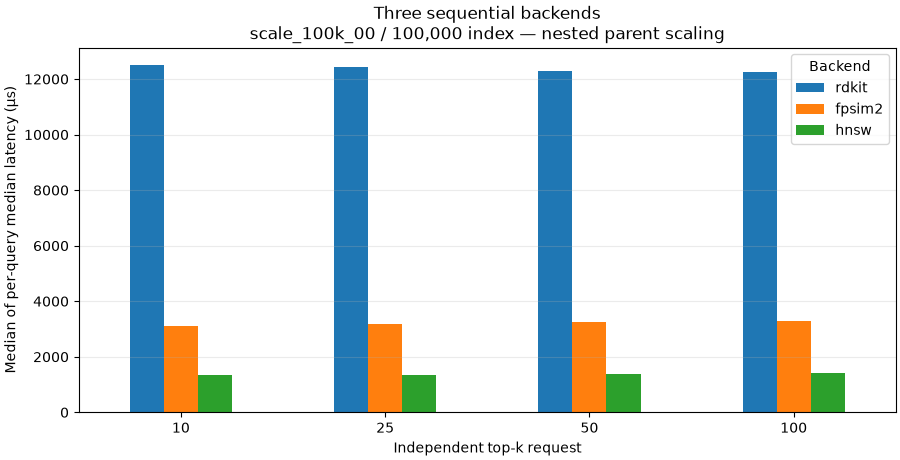

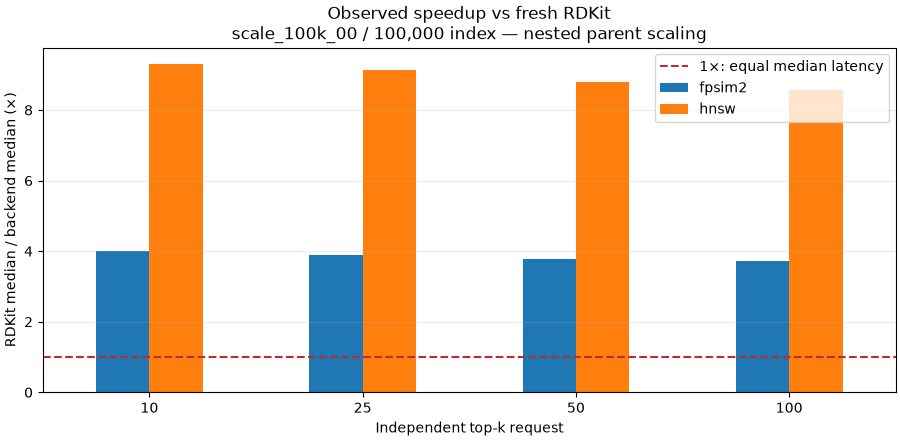

In [6]:
for path, report in zip(paths, reports):
    display(Markdown(f"## {report['experiment']}: {report['package']} / {report['index_size']:,}"))
    for title, table in tables(report).items():
        display(Markdown(f'**{title}**'))
        if title == 'Top-k-limited threshold recall':
            table = table.copy()
            table['mean_defined_recall'] = table['mean_defined_recall'].map(lambda v: 'undefined' if pd.isna(v) else round(v, 6))
        display(table.round(3))
    if report['passed']:
        for name in report['charts']:
            if name.endswith('.png') and not name.startswith('recall_vs_latency'):
                display(Image(filename=str(path/name)))
    else:
        print('Failed validation:', report['error'], '— comparative speed unavailable.')

## Separate experiment overview
These derived figures use the same completed runs, with no new construction or retrieval. Marker shapes identify k without crowded point labels. Parent scaling plots use only that parent's observations; graph construction is shown separately for the pilot and parent. Original per-run charts remain preserved.

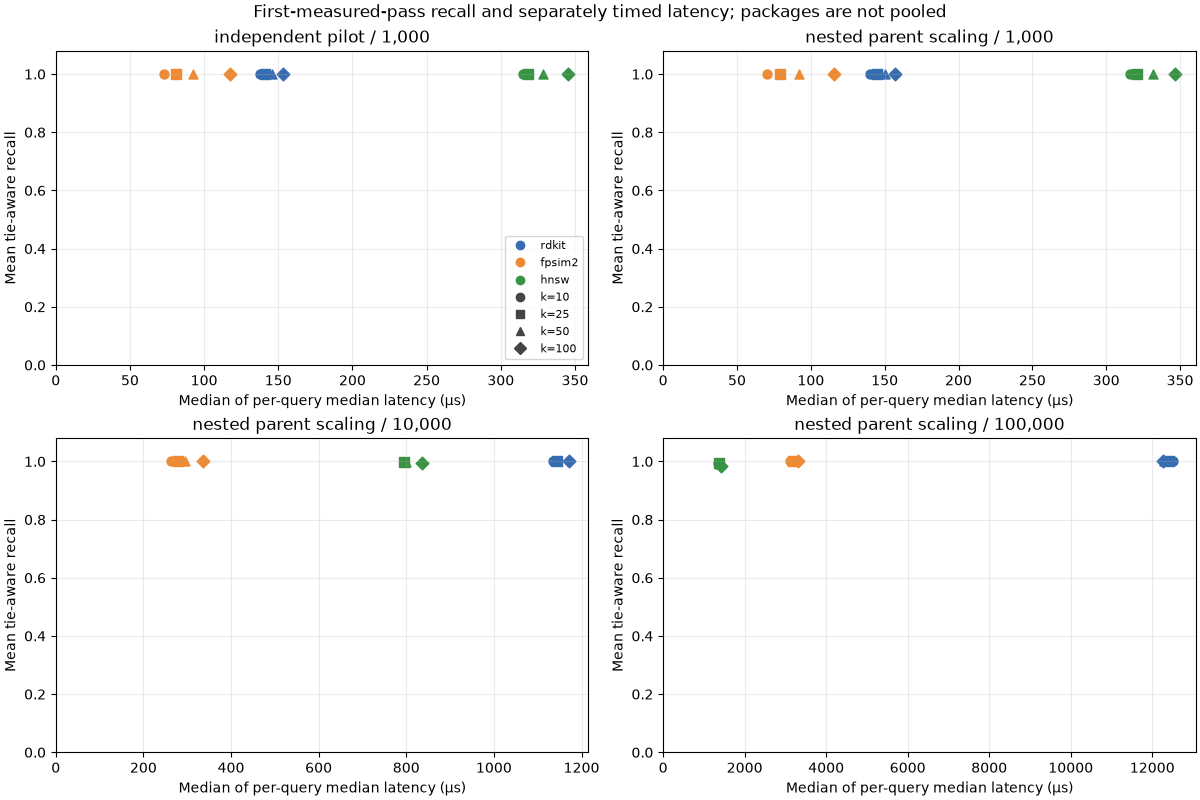

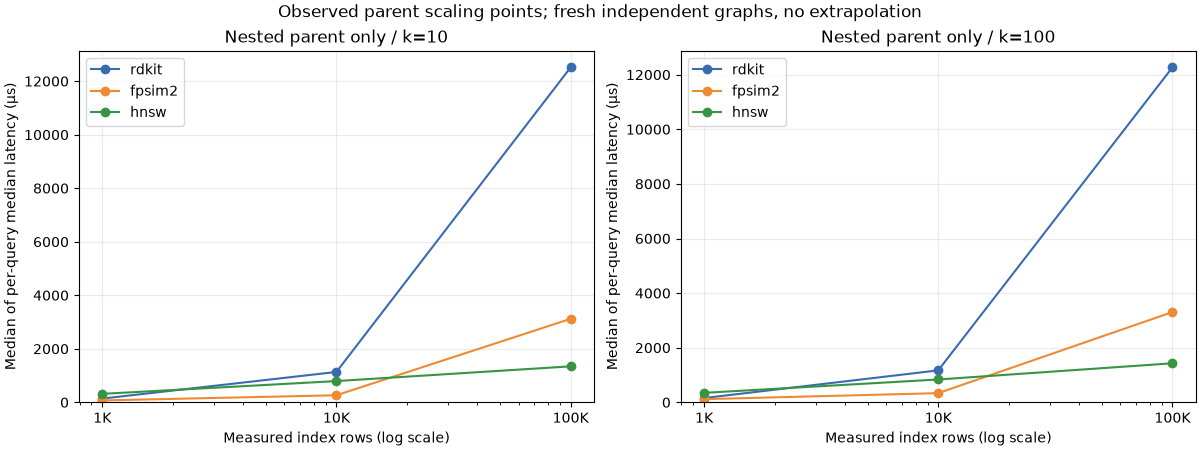

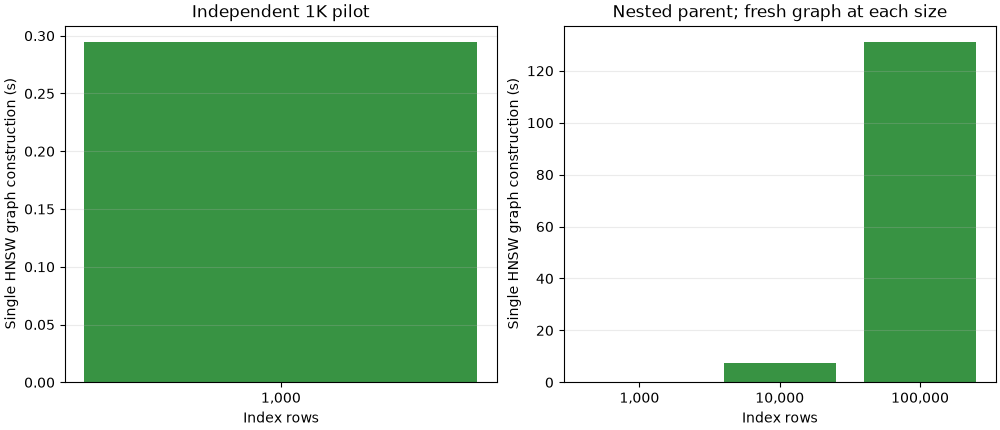

In [7]:
from chemtellect import fingerprint_store as store
OVERVIEW_RUN = ROOT/'experiments/results/hnsw/overview/run_3dd3907052824fc0be21e25dc8d24a09'
marker = json.loads((OVERVIEW_RUN/'manifest.json').read_text())
metadata = json.loads((OVERVIEW_RUN/'metadata.json').read_text())
if marker['status'] != 'complete':
    raise ValueError('Incomplete derived overview.')
for name, expected in marker['files'].items():
    if store.file_info(OVERVIEW_RUN/name) != expected:
        raise ValueError(f'Overview checksum mismatch: {name}')
if [s['path'] for s in metadata['source_runs']] == [str(p.relative_to(ROOT)) for p in paths]:
    for source in metadata['source_runs']:
        if store.file_info(ROOT/source['path']/'manifest.json') != source['manifest']:
            raise ValueError('Overview source run changed.')
    for name in metadata['charts']:
        if name.endswith('.png'):
            display(Image(filename=str(OVERVIEW_RUN/name)))
else:
    print('This derived overview belongs to different completed runs; use the per-run reports above.')

## Interpretation
Each latency is a median/mean or p95 **of per-query five-pass medians**, with linear percentiles. Each k is an independent request. All backends use matching query permutations and alternating recorded backend order. Total latency includes required selection/normalization; query conversion, graph construction, reference computation, correctness checks, recall evaluation, plots and writes are separate costs.

Recall uses only first-measured-pass candidates. Tie-aware top-k recall credits strict winners plus the available exact-boundary slots; extra boundary ties cannot replace missing strict winners. Threshold recall uses the complete inclusive float64 qualifying set and is top-k limited. Empty qualifying sets are undefined and counted. Native score/distance tolerances never enter recall.

The parent rows are nested, **graph topology is not**. The independent pilot is not pooled with them. RAM/RSS snapshots are not peaks. These are one-build, in-memory observations under a lossy fingerprint representation and uncontrolled scheduling/cache conditions, with no measured 100M result or reliable 100M prediction.